# Tarea 5 · Diseño de una CNN compacta con Global Average Pooling (PyTorch)

---

**Lucy Torres Durante**

**Introducción a la Ciencia de Datos 2026** · Tarea sobre la práctica [ICD - 21: Redes neuronales convolucionales](https://github.com/husseinlopez/icd2026/blob/main/icd-21-cnn.ipynb)

**Objetivo.** Diseñar una CNN con *Global Average Pooling* (GAP) que supere **95 % de exactitud en validación** en MNIST y use **menos de 54 330 parámetros entrenables**, el total de la CNN base con Flatten. Entre las arquitecturas que cumplan ambos requisitos elegir la de **menos parámetros**. Después, medir qué tan bien reconoce los dígitos cuando cambia su posición.

Esta versión reescribe el Notebook de la tarea en **PyTorch** (se ejecutó con `torch` para ROCm sobre una AMD Radeon RX 9070 XT; corre igual en CPU). Se usan las mismas particiones de MNIST y el margen negro de cuatro píxeles del notebook de la sesión. Los modelos de referencia de la ejecución guardada del curso son:

| Modelo base | Parámetros entrenables | Exactitud validación | Prueba a 0 px | Prueba a 4 px |
|---|---|---|---|---|
| CNN + Flatten | 54 330 | 96.87 % | 97.15 % | 37.21 % |
| CNN + GAP | 2 650 | 44.07 % | 46.35 % | 46.38 % |

El GAP base casi no cambia al desplazar las imágenes, pero parte de una exactitud muy baja: su curva es plana, aunque a un nivel inútil. La tarea es obtener una arquitectura que clasifique bien desde el inicio y medir cuánto de ese rendimiento conserva al mover los dígitos.

## 1. Preparar los datos

Mismas particiones y margen del notebook: subconjuntos estratificados con semilla 42 (**8 000 entrenamiento, 1 500 validación, 2 000 prueba**), cuatro píxeles de margen negro a cada lado en las tres particiones, de modo que se pueda desplazar un dígito hasta cuatro píxeles sin recortarlo. La forma que recibe la red es **36 × 36 × 1**. MNIST se descarga de la misma fuente que usa `keras.datasets.mnist`, así que los arreglos son idénticos a los de la práctica; PyTorch solo los reordena con canales primero (`N × 1 × 36 × 36`).

In [1]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.model_selection import train_test_split

SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4
LOTE = 128
EPOCAS = 20
TASA = 0.001
LIMITE_PARAMS = 54_330   # total de la CNN base con Flatten
UMBRAL_VAL = 95.0        # exactitud mínima de validación exigida
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# MNIST: los mismos arreglos que keras.datasets.mnist.load_data()
RUTA_MNIST = os.path.expanduser("~/.cache/mnist.npz")
if not os.path.exists(RUTA_MNIST):
    os.makedirs(os.path.dirname(RUTA_MNIST), exist_ok=True)
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", RUTA_MNIST,
    )
with np.load(RUTA_MNIST) as datos:
    (x_des, y_des), (x_test, y_test) = (datos["x_train"], datos["y_train"]), (datos["x_test"], datos["y_test"])

i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]        # 36 × 36 × 1, canales al final como en el notebook del curso

# PyTorch usa canales primero: N × 1 × 36 × 36
def a_tensor(X, y=None):
    X_t = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()
    return X_t if y is None else (X_t, torch.from_numpy(y.astype(np.int64)))

X_ent_t, y_ent_t = a_tensor(X_ent, y_ent)
X_val_t, y_val_t = a_tensor(X_val, y_val)
X_prueba_t, y_prueba_t = a_tensor(X_prueba, y_prueba)

print("Dispositivo:", DISPOSITIVO,
      torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "(CPU)")
for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

Dispositivo: cuda AMD Radeon RX 9070 XT
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


## 2. Modelos de referencia

`crear_cnn` es el espejo en PyTorch de la función del curso, extendida con dos decisiones nuevas: el tamaño del kernel (`kernel`, 3 por defecto) y la ubicación del pooling (`pooling` acepta, además de `"max"`, `"average"` y `"sin"`, el número de la convolución tras la cual se aplica). La cabeza GAP es `AdaptiveAvgPool2d(1)` seguida de `Flatten`: promedia cada mapa completo en un solo número, igual que `GlobalAveragePooling2D`.

La configuración de entrenamiento es la misma de la práctica: **Adam con tasa 0.001, lote 128, 20 épocas, semilla 42** y el mismo orden de mezcla para todas las variantes (un `torch.Generator` sembrado con la semilla dentro de cada llamado a `entrenar`, que además reinicia la semilla global antes de construir cada modelo, como `keras.utils.set_random_seed`). El protocolo exige **20 épocas** y registrar la validación al final de ese presupuesto.

Para que la comparación final ocurra en un mismo entorno, se entrenan **CNN + Flatten** (54 330 parámetros, el límite de la tarea) y **GAP base** (2 650 parámetros): la misma arquitectura `(16, 16)` del notebook con cabeza GAP.

In [2]:
def crear_cnn(filtros=(16, 16), padding="same", pooling="max", stride=1,
              cabeza="flatten", kernel=3):
    if padding == "same" and stride != 1:
        raise ValueError("padding='same' solo está soportado con stride 1.")
    capas, canales, alto, ancho = [], 1, FORMA[0], FORMA[1]
    for i, n_filtros in enumerate(filtros):
        p = kernel // 2 if padding == "same" else 0
        capas += [
            nn.Conv2d(canales, n_filtros, kernel,
                      stride=stride if i == 0 else 1, padding=p),
            nn.ReLU(),
        ]
        canales = n_filtros
        alto = alto + 2 * p - kernel + 1
        ancho = ancho + 2 * p - kernel + 1
        if isinstance(pooling, int) and pooling == i + 1:   # pooling tras la conv elegida
            capas.append(nn.MaxPool2d(2))
            alto, ancho = alto // 2, ancho // 2
    if pooling == "max":
        capas.append(nn.MaxPool2d(2))
        alto, ancho = alto // 2, ancho // 2
    elif pooling == "average":
        capas.append(nn.AvgPool2d(2))
        alto, ancho = alto // 2, ancho // 2
    elif isinstance(pooling, int) or pooling == "sin":
        pass
    else:
        raise ValueError("pooling debe ser 'max', 'average', un número de convolución o 'sin'")

    if cabeza == "flatten":
        capas.append(nn.Flatten())
        longitud = alto * ancho * canales
    elif cabeza == "gap":
        capas += [nn.AdaptiveAvgPool2d(1), nn.Flatten()]   # promedio global por mapa
        longitud = canales
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")
    capas.append(nn.Linear(longitud, 10))

    modelo = nn.Sequential(*capas)
    modelo.mapas = (alto, ancho, canales)   # forma que llega a la cabeza, para la tabla
    return modelo

def lotes(X, y=None, mezclar=False):
    generador = torch.Generator().manual_seed(SEMILLA)   # mismo orden de mezcla por modelo
    datos = torch.utils.data.TensorDataset(X) if y is None else torch.utils.data.TensorDataset(X, y)
    return torch.utils.data.DataLoader(datos, batch_size=LOTE, shuffle=mezclar,
                                       generator=generador)

def predecir(modelo, X_t, lote=256):
    modelo.eval()
    partes = []
    with torch.no_grad():
        for i in range(0, len(X_t), lote):
            salida = modelo(X_t[i:i + lote].to(DISPOSITIVO)).argmax(dim=1)
            partes.append(salida.cpu().numpy())
    return np.concatenate(partes)

def entrenar(constructor, **configuracion):
    torch.manual_seed(SEMILLA)          # como keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion).to(DISPOSITIVO)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA)
    perdida = nn.CrossEntropyLoss()    # equivale a softmax + entropía cruzada dispersa
    historial = {"loss": [], "val_accuracy": []}
    cargador_ent = lotes(X_ent_t, y_ent_t, mezclar=True)
    for _ in range(EPOCAS):
        modelo.train()
        acumulado = 0.0
        for xb, yb in cargador_ent:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador.zero_grad()
            l = perdida(modelo(xb), yb)
            l.backward()
            optimizador.step()
            acumulado += l.item() * len(xb)
        historial["loss"].append(acumulado / len(X_ent_t))
        historial["val_accuracy"].append(100 * np.mean(predecir(modelo, X_val_t) == y_val))
    return modelo, historial

def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o",
            label=etiqueta, color=color)

def resumen_cnn(nombre, modelo, historial):
    return {
        "Modelo": nombre,
        "Parámetros entrenables": sum(p.numel() for p in modelo.parameters()),
        "Exactitud validación (%)": historial["val_accuracy"][-1],   # ya está en %
        "Mapas antes del vector": " × ".join(str(d) for d in modelo.mapas),
    }

print("Entrenando CNN + Flatten (referencia)")
modelo_cnn, hist_cnn = entrenar(crear_cnn)                                   # cabeza flatten
print("Entrenando CNN + GAP base (referencia)")
modelo_gap, hist_gap = entrenar(crear_cnn, cabeza="gap")                     # (16, 16)
display(pd.DataFrame([
    resumen_cnn("CNN + Flatten", modelo_cnn, hist_cnn),
    resumen_cnn("GAP base", modelo_gap, hist_gap),
]).round(2))

Entrenando CNN + Flatten (referencia)
Entrenando CNN + GAP base (referencia)


,Modelo,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector
0,CNN + Flatten,54330,96.67,18 × 18 × 16
1,GAP base,2650,37.87,18 × 18 × 16


## 3. Explorar arquitecturas con GAP

El vector del GAP base sufre dos problemas. Primero, **dilución**: el promedio global recorre mapas de 18 × 18 en los que el dígito ocupa solo una parte; el margen negro aporta ceros que empujan todos los promedios hacia abajo. Segundo, **campo receptivo pequeño**: con dos convoluciones de 3 × 3, cada mapa solo ve estructuras de 5 × 5 píxeles, así que su promedio indica cuánta «textura local» hay, pero casi nada de la forma global del dígito. Con solo 16 promedios de este tipo, la capa lineal no puede separar las clases.

La exploración ataca ambos problemas con las decisiones que sugiere la práctica — número de filtros, profundidad, tamaño de los kernels y ubicación del pooling — más el `padding`, que el propio notebook ya exploraba. Todas las variantes usan cabeza GAP y el mismo presupuesto de 20 épocas:

| Variante | Filtros | Cambio respecto al GAP base | Parámetros esperados |
|---|---|---|---|
| GAP base | (16, 16) | — | 2 650 |
| GAP · 24 filtros | (24, 24) | **un solo cambio**: ancho | 5 698 |
| GAP · 3 capas | (16, 16, 16) | **un solo cambio**: profundidad | 4 970 |
| GAP · kernel 5 | (16, 16) | **un solo cambio**: tamaño de los kernels (3 → 5) | 7 002 |
| GAP · pool tras conv 1 | (16, 16) | **un solo cambio**: ubicación del pooling | 2 650 |
| GAP · 5 capas, k5, valid | (16 × 5) | combinación: kernels 5, profundidad y sin margen | 26 250 |
| GAP · 6 capas, k4, valid | (16 × 6) | combinación con kernels un poco más chicos | 21 002 |
| GAP · 6 capas, k5, valid | (16 × 6) | combinación: kernels 5, profundidad y sin margen | 32 666 |
| GAP · 3 capas, k9, valid | (16, 16, 16) | combinación: kernels 9 y sin margen | 42 986 |
| GAP · 2 capas, k13, valid | (16, 16) | combinación: kernels 13 y sin margen | 46 170 |

Las primeras cuatro filas cambian **una sola decisión** a la vez, así que el efecto del ancho, la profundidad, el tamaño del kernel y la ubicación del pooling se lee comparando contra el GAP base. Las últimas cinco combinan estos hallazgos: `padding="valid"` recorta el margen, de modo que el promedio global se toma sobre mapas compactos centrados en el contenido del dígito y no sobre el marco negro.

La selección usa **validación**: entre las variantes con más de 95 % de exactitud en validación y menos de 54 330 parámetros, se retiene la de menos parámetros. Prueba queda reservada para la comparación final.

Entrenando GAP · 24 filtros · {'filtros': (24, 24)}
  -> validación: 40.47 %
Entrenando GAP · 3 capas · {'filtros': (16, 16, 16)}
  -> validación: 43.93 %
Entrenando GAP · kernel 5 · {'kernel': 5}
  -> validación: 68.40 %
Entrenando GAP · pool tras conv 1 · {'pooling': 1}
  -> validación: 37.87 %
Entrenando GAP · 5 capas, k5, valid · {'filtros': (16, 16, 16, 16, 16), 'kernel': 5, 'padding': 'valid'}
  -> validación: 92.87 %
Entrenando GAP · 6 capas, k4, valid · {'filtros': (16, 16, 16, 16, 16, 16), 'kernel': 4, 'padding': 'valid'}
  -> validación: 93.07 %
Entrenando GAP · 6 capas, k5, valid · {'filtros': (16, 16, 16, 16, 16, 16), 'kernel': 5, 'padding': 'valid'}
  -> validación: 96.07 %
Entrenando GAP · 3 capas, k9, valid · {'filtros': (16, 16, 16), 'kernel': 9, 'padding': 'valid'}
  -> validación: 96.93 %
Entrenando GAP · 2 capas, k13, valid · {'filtros': (16, 16), 'kernel': 13, 'padding': 'valid'}
  -> validación: 95.13 %


,Modelo,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector
0,CNN + Flatten,54330,96.67,18 × 18 × 16
1,GAP base,2650,37.87,18 × 18 × 16
2,GAP · 24 filtros,5698,40.47,18 × 18 × 24
3,GAP · 3 capas,4970,43.93,18 × 18 × 16
4,GAP · kernel 5,7002,68.40,18 × 18 × 16
5,GAP · pool tras conv 1,2650,37.87,18 × 18 × 16
6,"GAP · 5 capas, k5, valid",26250,92.87,8 × 8 × 16
7,"GAP · 6 capas, k4, valid",21002,93.07,9 × 9 × 16
8,"GAP · 6 capas, k5, valid",32666,96.07,6 × 6 × 16
9,"GAP · 3 capas, k9, valid",42986,96.93,6 × 6 × 16


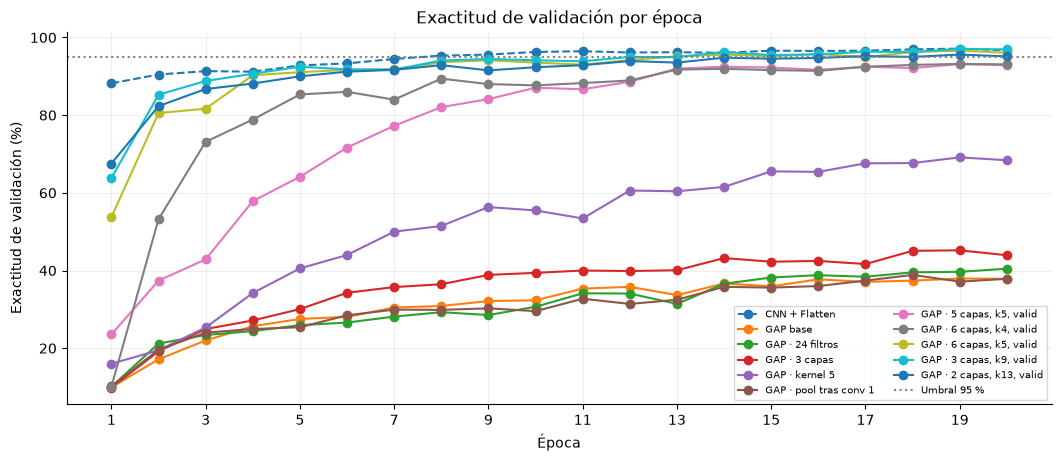

In [3]:
variantes = {
    "GAP base": {},
    "GAP · 24 filtros": {"filtros": (24, 24)},
    "GAP · 3 capas": {"filtros": (16, 16, 16)},
    "GAP · kernel 5": {"kernel": 5},
    "GAP · pool tras conv 1": {"pooling": 1},
    "GAP · 5 capas, k5, valid": {"filtros": (16,) * 5, "kernel": 5, "padding": "valid"},
    "GAP · 6 capas, k4, valid": {"filtros": (16,) * 6, "kernel": 4, "padding": "valid"},
    "GAP · 6 capas, k5, valid": {"filtros": (16,) * 6, "kernel": 5, "padding": "valid"},
    "GAP · 3 capas, k9, valid": {"filtros": (16, 16, 16), "kernel": 9, "padding": "valid"},
    "GAP · 2 capas, k13, valid": {"filtros": (16, 16), "kernel": 13, "padding": "valid"},
}

entrenadas = {"CNN + Flatten": (modelo_cnn, hist_cnn), "GAP base": (modelo_gap, hist_gap)}
for nombre, cambio in variantes.items():
    if nombre in entrenadas:   # GAP base ya se entrenó como referencia
        continue
    print(f"Entrenando {nombre} · {cambio}")
    entrenadas[nombre] = entrenar(crear_cnn, cabeza="gap", **cambio)
    print(f"  -> validación: {entrenadas[nombre][1]['val_accuracy'][-1]:.2f} %")

tabla_gap = pd.DataFrame([
    resumen_cnn(nombre, modelo, historial) for nombre, (modelo, historial) in entrenadas.items()
])
display(tabla_gap.round(2))

fig, ax = plt.subplots(figsize=(10.5, 4.5), layout="constrained")
for k, (nombre, (_, historial)) in enumerate(entrenadas.items()):
    estilo = "--" if "Flatten" in nombre else "-"
    curvas(ax, historial, "val_accuracy", nombre, f"C{k}", estilo)
ax.axhline(UMBRAL_VAL, color="gray", linestyle=":", label="Umbral 95 %")
ax.set(title="Exactitud de validación por época", xlabel="Época",
       ylabel="Exactitud de validación (%)", xticks=range(1, EPOCAS + 1, 2))
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.2)
plt.show()

### Selección con criterios de la tarea

In [4]:
# Entre las variantes GAP con más de 95 % de exactitud en validación y menos
# de 54 330 parámetros, se retiene la que tenga menos parámetros.
tabla_val = tabla_gap.rename(columns={"Modelo": "Variante"})
candidatos = tabla_val[
    (tabla_val["Exactitud validación (%)"] > UMBRAL_VAL)
    & (tabla_val["Parámetros entrenables"] < LIMITE_PARAMS)
    & tabla_val["Variante"].str.startswith("GAP")
]
if candidatos.empty:
    raise ValueError("Ninguna variante GAP cumple los dos requisitos de la tarea.")
elegida = candidatos.loc[candidatos["Parámetros entrenables"].idxmin()]
nombre_sel = elegida["Variante"]
modelo_sel, hist_sel = entrenadas[nombre_sel]

print(f"Variante seleccionada: {nombre_sel}")
print(f"Parámetros entrenables: {int(elegida['Parámetros entrenables'])}")
print(f"Exactitud de validación: {elegida['Exactitud validación (%)']:.2f} %")
print(
    f"Reducción frente a Flatten: {100 * (1 - elegida['Parámetros entrenables'] / sum(p.numel() for p in modelo_cnn.parameters())):.1f} %"
    f" ({sum(p.numel() for p in modelo_cnn.parameters()) - elegida['Parámetros entrenables']:.0f} parámetros menos)"
)
display(candidatos.sort_values("Parámetros entrenables").round(2))

Variante seleccionada: GAP · 6 capas, k5, valid
Parámetros entrenables: 32666
Exactitud de validación: 96.07 %
Reducción frente a Flatten: 39.9 % (21664 parámetros menos)


,Variante,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector
8,"GAP · 6 capas, k5, valid",32666,96.07,6 × 6 × 16
9,"GAP · 3 capas, k9, valid",42986,96.93,6 × 6 × 16
10,"GAP · 2 capas, k13, valid",46170,95.13,6 × 6 × 16


## 4. Efecto del desplazamiento

Se comparan **CNN + Flatten**, **GAP base** y la **variante GAP seleccionada** con los pesos con los que terminaron el entrenamiento, sobre las mismas 2 000 imágenes de prueba. `desplazar` es la función del notebook: mueve el dígito y rellena de negro. Se evalúa a **0, 2 y 4 píxeles**; para 2 y 4 se promedia la exactitud de los cuatro desplazamientos (arriba, abajo, izquierda y derecha). Sin reentrenar.

,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
Modelo,,,,
CNN + Flatten,97.35,84.19,37.55,59.80
CNN + GAP base,38.45,38.42,38.43,0.02
"CNN + GAP elegida (6 capas, k5, valid)",96.90,93.84,75.18,21.72


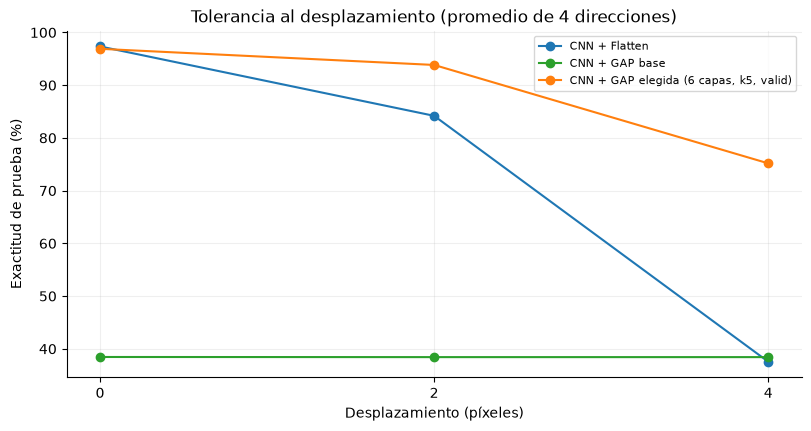

In [5]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

modelos = {
    "CNN + Flatten": modelo_cnn,
    "CNN + GAP base": modelo_gap,
    f"CNN + GAP elegida ({nombre_sel.split('·')[-1].strip()})": modelo_sel,
}
distancias = (0, 2, 4)
exactitudes = {
    nombre: [100 * np.mean(predecir(modelo, X_prueba_t) == y_prueba)]
    for nombre, modelo in modelos.items()
}
for distancia in distancias[1:]:
    for nombre, modelo in modelos.items():
        valores = [
            100 * np.mean(predecir(modelo, a_tensor(desplazar(X_prueba, dy, dx))) == y_prueba)
            for dy, dx in ((0, distancia), (0, -distancia), (distancia, 0), (-distancia, 0))
        ]
        exactitudes[nombre].append(float(np.mean(valores)))

tabla = pd.DataFrame.from_dict(exactitudes, orient="index",
                               columns=[f"{d} px (%)" for d in distancias])
tabla["Caída a 4 px (pp)"] = tabla["0 px (%)"] - tabla["4 px (%)"]
tabla.index.name = "Modelo"
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for nombre, color in zip(modelos, ("C0", "C2", "C1")):
    ax.plot(distancias, exactitudes[nombre], marker="o", label=nombre, color=color)
ax.set(title="Tolerancia al desplazamiento (promedio de 4 direcciones)",
       xlabel="Desplazamiento (píxeles)", ylabel="Exactitud de prueba (%)",
       xticks=distancias)
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()

## 5. Conclusión

**Qué aprendió la exploración.** El ancho no fue la palanca: pasar de 16 a 24 filtros dejó la validación en 40.47 %, apenas +2.6 pp sobre el GAP base (37.87 %). Promediar más mapas igual de locales no agrega información; GAP solo funciona si cada mapa promediado dice algo de la forma global del dígito. En esta ejecución la decisión individual con mayor efecto fue el **tamaño del kernel** (3 → 5), que sumó +30.5 pp (68.40 %); una capa más sumó +6.1 pp y adelantar el pooling tras la primera convolución no movió nada (37.87 %). Con `padding="same"` las variantes llegaron, como máximo, a 68.40 % (kernel 5): el promedio global seguía recorriendo mapas amplios donde el margen negro domina. Con `padding="valid"` y más capas los mapas se encogen (8 × 8, 9 × 9 o 6 × 6 antes del vector) y la validación saltó a 92.87–96.93 %. Ojo: esas variantes también cambian kernel y profundidad, así que no se aisló el efecto de `valid` por sí solo; con 6 capas de kernels 5 × 5 la validación llegó a 96.07 % con solo 32 666 parámetros.

**Respuestas a las preguntas de la tarea.**

1. **¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?** Que el promedio global recayera sobre mapas con campo receptivo amplio y centrados en el dígito: apilar **6 convoluciones de 16 filtros con kernels de 5 × 5** hace de cada mapa un detector de estructura grande, y `padding="valid"` recorta el marco negro que GAP estaba promediando (antes del vector los mapas pasan de 18 × 18 a 6 × 6). De las decisiones individuales, el tamaño del kernel fue la más determinante (+30.5 pp); el número de filtros, en cambio, casi no movió la aguja.

2. **¿Cuántos parámetros ahorraste frente a Flatten?** El modelo elegido — **GAP · 6 capas de 16, kernel 5, valid** — usa 32 666 parámetros entrenables frente a los 54 330 de la CNN + Flatten: **21 664 parámetros menos, una reducción del 39.9 %**, con una validación prácticamente equivalente (96.67 % vs 96.07 %).

3. **¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia se aprecia la diferencia?** Sí. Sin desplazamiento Flatten apenas gana (97.35 % vs 96.90 %), pero la diferencia se aprecia **a partir de los 2 píxeles** (93.84 % vs 84.19 %, +9.6 pp) y a los 4 duplica la exactitud de Flatten (75.18 % vs 37.55 %, +37.6 pp). La caída del elegido es de 21.72 pp frente a los 59.80 pp de Flatten. La caída hay que leerla junto con el nivel que conserva cada modelo: el GAP base prácticamente no se cae (0.02 pp) pero se queda plano en un nivel inútil (≈ 38.4 % en todas las distancias), mientras que el GAP elegido conserva 75.18 % a 4 px, el doble que Flatten (37.55 %), y su caída es poco más de un tercio de la de Flatten (21.72 vs 59.80 pp). La combinación de vector corto (GAP), campo receptivo amplio y promedio centrado en el dígito da el mejor equilibrio entre tamaño (39.9 % de ahorro), exactitud (96.90 % en prueba sin desplazar) y tolerancia al desplazamiento.